# Identifikasi dan Klasifikasi Biner Data Anemia
Notebook ini berisi tahapan untuk melakukan klasifikasi biner pada dataset `d_output.csv`.


## Mengapa Dataset ini disebut Klasifikasi Biner?
Dataset ini dikategorikan sebagai masalah **Klasifikasi Biner (Binary Classification)** karena variabel target atau label yang ingin kita prediksi hanya memiliki **dua kemungkinan kelas atau kategori**. 

Jika kita melihat pada kolom `Anaemic`, nilai yang ada di dalamnya hanya ada dua, yaitu:
1. **'Yes'** (Positif Anemia)
2. **'No'** (Negatif Anemia)

Karena model machine learning yang akan kita bangun bertujuan untuk membedakan data ke dalam salah satu dari dua kelas tersebut, maka ini secara definitif adalah klasifikasi biner.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('d_output.csv')
display(df.head())
print("\nInformasi Dataset:")
df.info()


,Number,Sex,%Red Pixel,%Green pixel,%Blue pixel,Hb,Anaemic
0,1,M,43.170845,30.945626,25.921971,6.252659,Yes
1,2,F,43.163481,30.306974,26.759843,8.578865,Yes
2,3,F,46.269997,27.315656,26.028556,9.640936,Yes
3,4,F,45.054787,30.469816,24.460797,4.794217,Yes
4,5,M,45.061884,31.218572,24.071714,8.865329,Yes



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Number        500 non-null    int64  
 1   Sex           500 non-null    str    
 2   %Red Pixel    500 non-null    float64
 3   %Green pixel  500 non-null    float64
 4   %Blue pixel   500 non-null    float64
 5   Hb            500 non-null    float64
 6   Anaemic       500 non-null    str    
dtypes: float64(4), int64(1), str(2)
memory usage: 27.5 KB


## Data Preprocessing
Beberapa hal yang perlu dilakukan:
1. Menghapus kolom `Number` karena hanya berupa ID berurutan dan tidak relevan untuk pemodelan.
2. Membersihkan nilai pada kolom `Sex` (terdapat spasi berlebih seperti 'M ' dan 'F ').
3. Mengubah nilai kategorikal pada `Sex` dan target `Anaemic` menjadi numerik agar bisa diproses oleh algoritma Machine Learning.


In [2]:
# 1. Menghapus kolom Number
df = df.drop('Number', axis=1)

# 2. Membersihkan spasi berlebih pada kolom Sex
df['Sex'] = df['Sex'].str.strip()
print("Kategori unik pada kolom Sex setelah dibersihkan:", df['Sex'].unique())

# 3. Label Encoding
# Sex: M=1, F=0
df['Sex'] = df['Sex'].map({'M': 1, 'F': 0})

# Target Anaemic: Yes=1, No=0
df['Anaemic'] = df['Anaemic'].map({'Yes': 1, 'No': 0})

display(df.head())


Kategori unik pada kolom Sex setelah dibersihkan: <StringArray>
['M', 'F']
Length: 2, dtype: str


,Sex,%Red Pixel,%Green pixel,%Blue pixel,Hb,Anaemic
0,1,43.170845,30.945626,25.921971,6.252659,1
1,0,43.163481,30.306974,26.759843,8.578865,1
2,0,46.269997,27.315656,26.028556,9.640936,1
3,0,45.054787,30.469816,24.460797,4.794217,1
4,1,45.061884,31.218572,24.071714,8.865329,1


## Pemodelan Machine Learning (Klasifikasi Biner)
Kita akan membagi data menjadi set pelatihan (train) dan set pengujian (test), lalu melatih model klasifikasi menggunakan algoritma **Random Forest Classifier**.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Pisahkan fitur (X) dan target (y)
X = df.drop('Anaemic', axis=1)
y = df['Anaemic']

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Inisialisasi dan latih model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Prediksi pada data test
y_pred = model.predict(X_test)

print("Model selesai dilatih!")


Model selesai dilatih!


## Evaluasi Model
Mari kita lihat seberapa baik model ini dalam mengklasifikasikan (memprediksi) kelas 0 (Tidak Anemia) dan 1 (Anemia).


Akurasi Model: 100.00%

Classification Report:
              precision    recall  f1-score   support

      No (0)       1.00      1.00      1.00        50
     Yes (1)       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



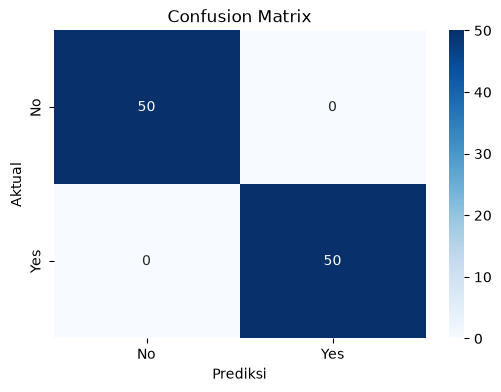

In [4]:
# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {accuracy * 100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No (0)', 'Yes (1)']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix')
plt.show()
